# Presión fiscal y PIB por habitante

In [ ]:
# Parámetros de la gráfica
SLUG = "fiscalidad"  # carpeta en research/temas/
GRAFICA_ID = "presion-fiscal-pib-per-capita"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Presión fiscal y PIB por habitante"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Presión fiscal", "unidad": "% del PIB"}
EJE_Y = {"titulo": "PIB por habitante", "unidad": "dólares PPA por habitante, precios corrientes"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE.

- **Eje horizontal:** la **presión fiscal**, todos los impuestos y cotizaciones sociales que recaudan las administraciones públicas en porcentaje del PIB (el mismo indicador que la gráfica `presion-fiscal`).
- **Eje vertical:** el **PIB por habitante** en dólares con la misma capacidad de compra (paridad de poder adquisitivo, PPA) a precios corrientes del mismo año, para que la renta de los países sea comparable.

**Para qué sirve.** Es la comparación que está detrás del llamado «esfuerzo fiscal» (la presión fiscal en relación con la renta por habitante): aquí no se calcula ese índice, solo se muestran los dos datos. **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.** La presión fiscal depende de cómo se financian las pensiones y la sanidad (con cotizaciones, impuestos o seguros privados) y no mide qué servicios se reciben a cambio.

## 2. Descarga

- **OCDE, Revenue Statistics** (`OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD`, versión 2.0): ingresos fiscales totales (`TAX_REV`, `S13`, `_T`) en % del PIB de los 38 países de la OCDE, y la media que publica la OCDE (`OECD_REP`).
- **OCDE, National Accounts at a Glance** (`OECD.SDD.NAD,DSD_NAAG@DF_NAAG_I`, versión 1.0): PIB por habitante (`B1GQ_POP`) en USD PPA a precios corrientes (`USD_PPP_PS`), y el agregado OCDE (`OECD`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import eurostat, oecd
from lib.paises import nombre_punto
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
HOY = date.today().isoformat()

DATAFLOW_REV = "OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0"
CLAVE_REV = "{AREA}.TAX_REV.S13._T._T.PT_B1GQ.A"  # la misma clave que presion-fiscal
DATAFLOW_PIB = "OECD.SDD.NAD,DSD_NAAG@DF_NAAG_I,1.0"
CLAVE_PIB = "A.{AREA}.B1GQ_POP.USD_PPP_PS.NAAG_I"

x, _ = oecd.get(DATAFLOW_REV, CLAVE_REV, areas=AREAS, desde=DESDE)
y, _ = oecd.get(DATAFLOW_PIB, CLAVE_PIB, areas=AREAS, desde=DESDE)
# Medias: Revenue Statistics publica la media simple (OECD_REP) y las cuentas nacionales el agregado (OECD)
media_x, _ = oecd.get(DATAFLOW_REV, CLAVE_REV, areas={"OECD_REP": "OECD_REP", "OECD": "OECD"}, desde=DESDE)
media_y, _ = oecd.get(DATAFLOW_PIB, CLAVE_PIB, areas={"OECD_REP": "OECD_REP", "OECD": "OECD"}, desde=DESDE)
print("Medias publicadas, eje x:", sorted(media_x["serie"].unique()), "· eje y:", sorted(media_y["serie"].unique()))

Medias publicadas, eje x: ['OECD_REP'] · eje y: ['OECD']


## 3. Transformación

1. Los dos ejes se usan tal como los publica la OCDE, sin transformar.
2. **Sin punto de la media OCDE:** cada fuente publica una media distinta (Revenue Statistics, la media simple de los países; las cuentas nacionales, el agregado de la OCDE ponderado por tamaño), así que no hay un mismo concepto para los dos ejes.
3. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


misma_media = set(media_x["serie"]) & set(media_y["serie"])
assert not misma_media, f"las dos fuentes publican la misma media ({misma_media}): revisar si se añade el punto"
_, FLUJO_REV, VERSION_REV = DATAFLOW_REV.split(",")
_, FLUJO_PIB, VERSION_PIB = DATAFLOW_PIB.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_REV} (Revenue Statistics, versión {VERSION_REV}): TAX_REV, S13, _T (TOTALTAX), PT_B1GQ", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{FLUJO_PIB} (National Accounts at a Glance, versión {VERSION_PIB}): B1GQ_POP, USD_PPP_PS", oecd.URL_EXPLORER, HOY),
]
NOTAS = [
    f"Presión fiscal: OCDE, Revenue Statistics ({FLUJO_REV}, versión {VERSION_REV}): impuestos y cotizaciones sociales "
    "obligatorias recaudados por el conjunto de las administraciones públicas, en porcentaje del PIB.",
    f"PIB por habitante: OCDE, National Accounts at a Glance ({FLUJO_PIB}, versión {VERSION_PIB}), en dólares "
    "estadounidenses en paridad de poder adquisitivo (PPA) a precios corrientes del mismo año que la presión fiscal.",
    "No se calcula el índice de «esfuerzo fiscal» (presión fiscal dividida por la renta por habitante): solo se "
    "muestran los dos datos.",
    "Sin punto de la media OCDE: Revenue Statistics publica la media simple de los países (OECD_REP) y las cuentas "
    "nacionales el agregado ponderado (OECD), que no son el mismo concepto.",
]

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

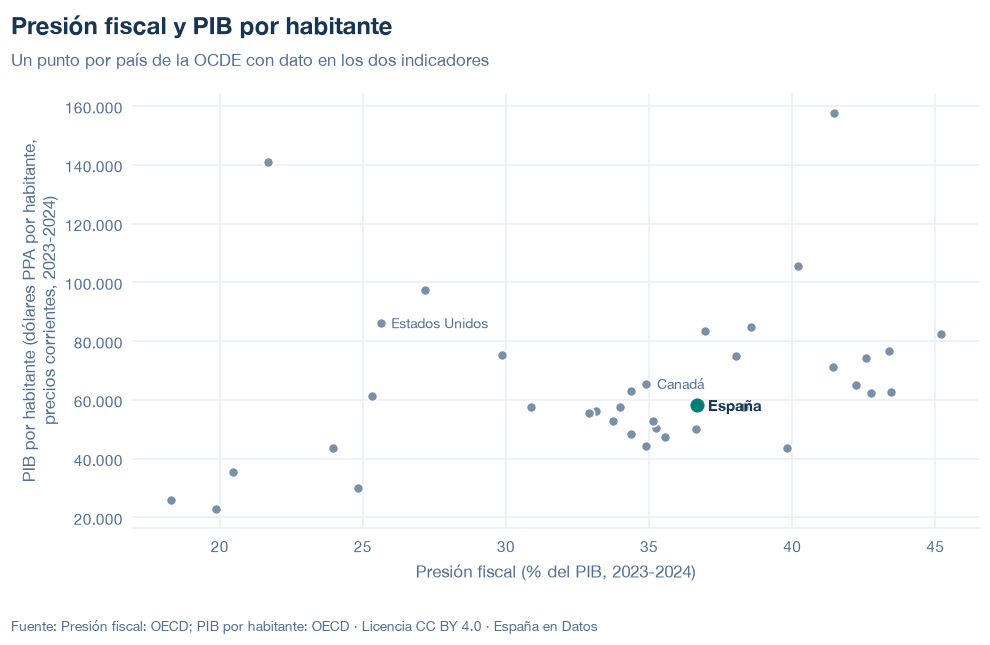

codigo  anio         x             y
   AUS  2023 29.867254  75161.720824
   AUT  2024 43.374411  76674.086851
   BEL  2024 42.571263  74276.558484
   CAN  2024 34.904570  65482.971712
   CHE  2024 27.169048  97357.187908
   CHL  2024 20.479447  35493.356435
   COL  2024 19.865884  23020.662394
   CRI  2024 24.840079  30064.067937
   CZE  2024 33.975018  57723.004954
   DEU  2024 38.021492  74946.986361
   DNK  2024 45.177061  82562.975214
   ESP  2024 36.682055  58188.840337
   EST  2024 35.231248  50354.314757
   FIN  2024 42.217254  65163.009713
   FRA  2024 43.462209  62647.913820
   GBR  2024 34.366806  63155.803902
   GRC  2024 39.826849  43641.807284
   HUN  2024 34.353895  48547.745606
   IRL  2024 21.694294 140847.502865
   ISL  2024 36.948753  83509.504009
   ISR  2024 30.877349  57449.865074
   ITA  2024 42.752192  62530.325651
   JPN  2023 33.733304  52796.051769
   KOR  2024 25.333638  61226.849353
   LTU  2024 33.129851  56260.806962
   LUX  2024 41.458699 157809.485553
 

In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/presion-fiscal-pib-per-capita.json y data/presion-fiscal-pib-per-capita.csv


## 6. Fuentes, notas y licencia

- OCDE, Revenue Statistics: `OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0` (`TAX_REV`, `S13`, `_T`, `PT_B1GQ`).
- OCDE, National Accounts at a Glance: `OECD.SDD.NAD,DSD_NAAG@DF_NAAG_I,1.0` (`B1GQ_POP`, `USD_PPP_PS`).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.